# 04 · Citas e índice h

Equivale a la sección 7 del paper ancla (pregunta 5).

El índice h se calcula sobre el conjunto de publicaciones de cada país: el mayor *h* tal que *h*
publicaciones tienen al menos *h* citas cada una.

**Advertencia de interpretación:** las citas se atribuyen a todos los países coautores por igual.
Con equipos internacionales grandes, una publicación muy citada eleva el índice de un país aunque
su participación haya sido menor. El paper ancla tiene la misma limitación.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from astroca.config import get_loader
from astroca.storage import DataStore
from astroca import viz

viz.aplicar_estilo()

loader = get_loader()
store = DataStore(loader.settings().data_dir)

pubs = store.read_latest_raw("publications")
aff = store.read_latest_processed("author_affiliations")
paises = {c.iso3: c.name for c in loader.countries().in_scope()}

print(f"publicaciones: {len(pubs)}   filas autor-afiliacion: {len(aff)}")

publicaciones: 273   filas autor-afiliacion: 1233


In [2]:
pubs_citas = pubs[["bibcode", "year", "title", "pub", "citation_count"]].copy()
pubs_citas["citation_count"] = pd.to_numeric(
    pubs_citas["citation_count"], errors="coerce").fillna(0).astype(int)

print(f"citas totales: {pubs_citas['citation_count'].sum():,}")
print(f"mediana por publicacion: {pubs_citas['citation_count'].median():.0f}")
print(f"publicaciones sin citas: {(pubs_citas['citation_count'] == 0).sum()}")

citas totales: 7,387
mediana por publicacion: 12
publicaciones sin citas: 24


## Métricas de impacto por país

In [3]:
region = aff[aff["iso3"].notna()]
citas_por_bib = pubs_citas.set_index("bibcode")["citation_count"]

filas = []
for iso3, grupo in region.groupby("iso3"):
    bibcodes = grupo["bibcode"].unique()
    citas = citas_por_bib.reindex(bibcodes).dropna()
    filas.append({
        "país": paises.get(iso3, iso3),
        "publicaciones": len(bibcodes),
        "citas": int(citas.sum()),
        "citas/publicación": round(citas.mean(), 1),
        "índice h": viz.indice_h(citas.tolist()),
    })

impacto = (pd.DataFrame(filas)
           .set_index("país")
           .sort_values("citas", ascending=False))
display(impacto)

,publicaciones,citas,citas/publicación,índice h
país,,,,
Costa Rica,155,4030,26.0,33
Panama,47,2413,51.3,25
Guatemala,37,443,12.0,11
Nicaragua,14,345,24.6,9
El Salvador,12,174,14.5,6
Honduras,14,145,10.4,6
Belice,1,20,20.0,1


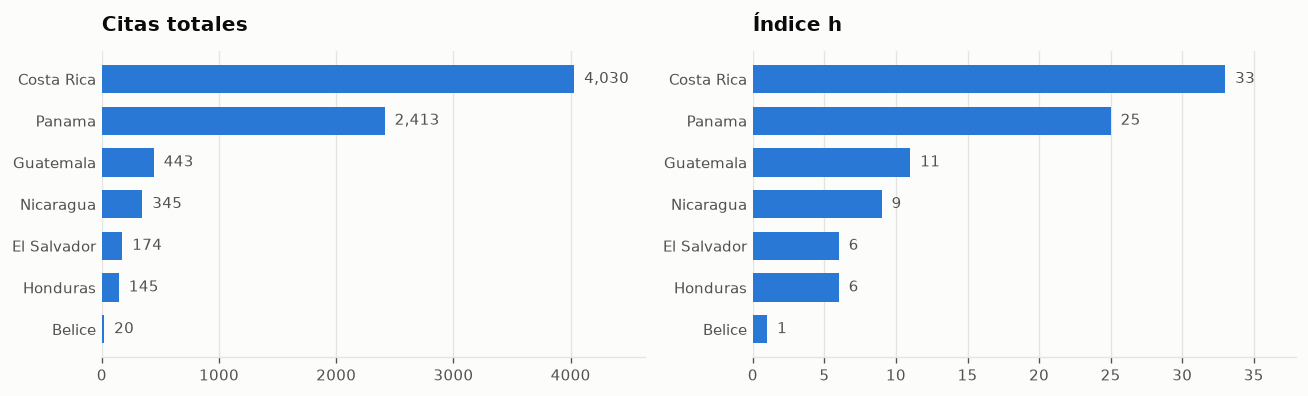

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

viz.barras_horizontales(axes[0], impacto.index.tolist(), impacto["citas"].tolist())
viz.titulo(axes[0], "Citas totales")

orden_h = impacto.sort_values("índice h", ascending=False)
viz.barras_horizontales(axes[1], orden_h.index.tolist(), orden_h["índice h"].tolist())
viz.titulo(axes[1], "Índice h")

plt.tight_layout()
plt.show()

## Volumen frente a impacto

Cada punto es un país. La posición en el eje horizontal es cuánto publica; la vertical, cuántas
citas acumula. Un país por encima de la diagonal implícita rinde más de lo que su volumen
anticiparía.

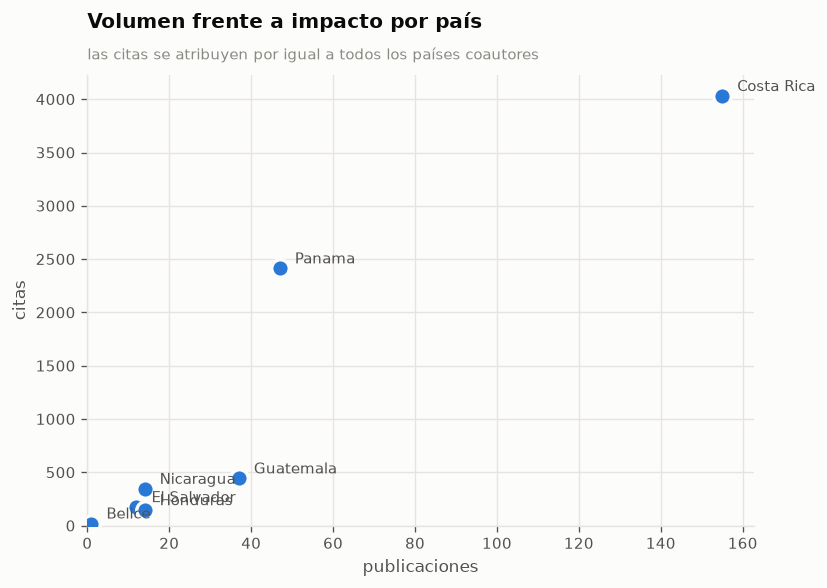

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(impacto["publicaciones"], impacto["citas"],
           s=110, color=viz.SERIE_1, zorder=3,
           edgecolor=viz.SUPERFICIE, linewidth=2)

for nombre, fila in impacto.iterrows():
    ax.annotate(nombre, (fila["publicaciones"], fila["citas"]),
                xytext=(9, 3), textcoords="offset points",
                fontsize=9, color=viz.TINTA_SECUNDARIA)

viz.limpiar_ejes(ax)
ax.set_xlabel("publicaciones")
ax.set_ylabel("citas")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
viz.titulo(ax, "Volumen frente a impacto por país",
           "las citas se atribuyen por igual a todos los países coautores")
plt.tight_layout()
plt.show()

## Publicaciones más citadas de la región

In [6]:
top = pubs_citas.nlargest(12, "citation_count").copy()
top["title"] = top["title"].str[:72]
top["pub"] = top["pub"].astype(str).str[:34]
display(top[["year", "citation_count", "title", "pub"]]
        .rename(columns={"citation_count": "citas", "year": "año",
                         "title": "título", "pub": "revista"})
        .reset_index(drop=True))

,año,citas,título,revista
0,1996,506,Reconciliation of late Quaternary sea levels d...,Earth and Planetary Science Letter
1,1993,352,Duality symmetries from non-abelian isometries...,Nuclear Physics B
2,2006,231,Speciation by hybridization in Heliconius butt...,Nature
3,2009,146,A World-Wide Net of Solar Radio Spectrometers:...,Earth Moon and Planets
4,2012,146,Analytical properties of Einasto dark matter h...,Astronomy and Astrophysics
5,2019,142,The spin structure of the nucleon,Reports on Progress in Physics
6,2003,141,Contrasting He-C relationships in Nicaragua an...,Earth and Planetary Science Letter
7,2012,139,Improved ambient noise correlation functions u...,Geophysical Journal International
8,2018,133,Understanding and forecasting phreatic eruptio...,"Earth, Planets and Space"
9,2015,130,Earthquake magnitude calculation without satur...,Geophysical Research Letters


## Dónde se publica

Permite verificar el alcance real del filtro `database:astronomy`.

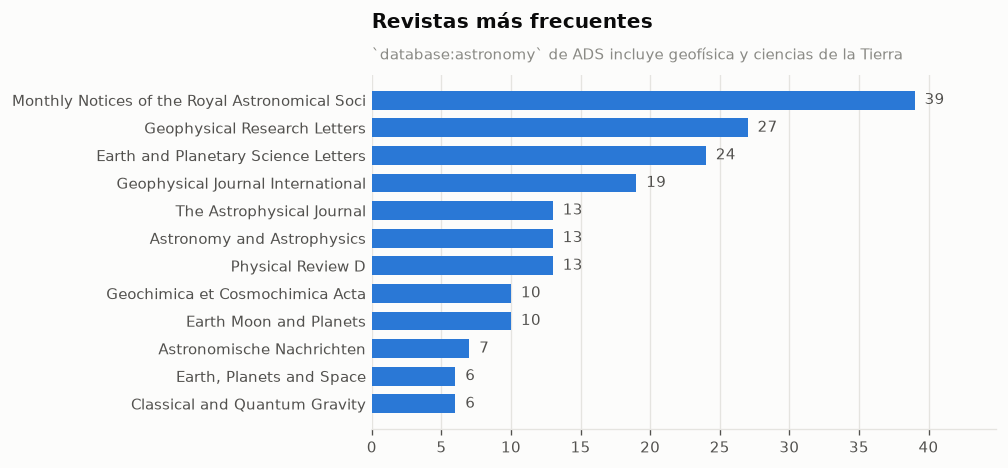

publicaciones en revistas de ciencias de la Tierra: 106 (39% del total)
Decision pendiente: filtrarlas o documentar que el criterio es 'lo que ADS clasifica'.


In [7]:
revistas = pubs["pub"].value_counts().head(12)

fig, ax = plt.subplots(figsize=(8.5, 4))
viz.barras_horizontales(ax, [str(r)[:46] for r in revistas.index], revistas.values.tolist())
viz.titulo(ax, "Revistas más frecuentes",
           "`database:astronomy` de ADS incluye geofísica y ciencias de la Tierra")
plt.tight_layout()
plt.show()

tierra = ["Geophysical", "Earth", "Geochimica", "Tectonophysics", "Journal of Volcanology"]
es_tierra = pubs["pub"].astype(str).str.contains("|".join(tierra), case=False, na=False)
print(f"publicaciones en revistas de ciencias de la Tierra: {es_tierra.sum()} "
      f"({es_tierra.sum() / len(pubs):.0%} del total)")
print("Decision pendiente: filtrarlas o documentar que el criterio es 'lo que ADS clasifica'.")